# Does forgetting really get *worse* for facts the model sees more often?

A premise this project carried for a while is that **frequently-attested facts are
forgotten more**. That would be a genuinely surprising result, because it cuts
against the three papers closest to this setting:

- **Kandpal et al. (2023)**, *Large Language Models Struggle to Learn Long-Tail Knowledge* (ICML) — recall accuracy rises sharply with the number of pretraining documents that state the fact.
- **Mallen et al. (2023)**, *When Not to Trust Language Models* (ACL) — parametric recall is reliable only for popular entities; the tail is where models fail.
- **Chang et al. (2024)**, *How Do LLMs Acquire Factual Knowledge During Pretraining?* (NeurIPS) — duplicated facts decay **more slowly** after acquisition.

So the premise is worth testing carefully rather than assuming. This notebook does
exactly one thing: it measures how forgetting relates to fact frequency in the LMEnt
13-checkpoint panel, and shows that the answer flips depending on **which statistic
you compute**.

### The one distinction that decides the answer

A fact can only be *observed* to be forgotten at a checkpoint where it is currently
correct. So there are two different quantities:

|  | definition | what it confounds |
|---|---|---|
| **forgetting count** (Toneva et al., 2019) | how many times a fact went correct → wrong | how *often it was correct at all* |
| **forgetting hazard** | P(wrong at $t{+}1$ \| correct at $t$) | nothing — it is normalised by opportunity |

Frequent facts are correct at far more checkpoints, so they have far more chances to
be seen forgetting. Counting events and measuring the rate can therefore point in
**opposite directions** — and here they do.

### Two notions of "frequency"

Frequency is not one variable, and the two available here separate cleanly:

- `num_shared_chunks` — training chunks in which the subject and the answer co-occur: **evidence for this specific fact**.
- `total_subj_chunks` — training chunks mentioning the subject at all: **how famous the entity is**.

They correlate only ρ ≈ 0.36 on the log scale, so they are worth reporting separately.

> *Scope note.* This dataset is the **top-10 % exposure slice** of PopQA-KAS, so even
> the lowest quintile has ≈ 42 supporting chunks. The genuine long tail that Kandpal
> et al. study is not sampled here; every statement below is about variation *within*
> a well-attested set.


---
## 1 — Data: a fact × checkpoint recall panel, plus the frequency features

13 checkpoints (50 k → 658 032 steps) of 15-shot recall over 1 452 PopQA-KAS facts.
Facts whose answer leaks into the few-shot prompt are marked `excluded` and dropped
(this is a property of the fact, so the surviving set is identical at every
checkpoint and the panel stays balanced).

In [1]:
import glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# --- visual style, shared with the other notebooks in this project ---
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"          # validated pair (OKLab dE 33.6 normal, 24.7 CVD)
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
PCT = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

def clean(ax):
    """Recessive axes: horizontal grid only, no spines, no ticks."""
    ax.grid(axis="y", alpha=.4)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

In [2]:
TRAJ_DIR = "data/artifacts/recall/rotemab_15shot_top10_internal"
files = sorted(glob.glob(f"{TRAJ_DIR}/*.parquet"),
               key=lambda f: int(re.search(r"step(\d+)", f).group(1)))
steps = [int(re.search(r"step(\d+)", f).group(1)) for f in files]

# --- fact x checkpoint matrices -------------------------------------------------
frames = []
for f, s in zip(files, steps):
    d = pd.read_parquet(f)
    d = d[~d["excluded"]].copy()
    d["step"] = s
    frames.append(d[["id", "step", "correct", "is_top1", "gold_prob"]])
long = pd.concat(frames, ignore_index=True)

def panel(col):
    return long.pivot(index="id", columns="step", values=col).reindex(columns=steps)

correct   = panel("correct").to_numpy().astype(bool)     # (n_facts, n_steps)
is_top1   = panel("is_top1").to_numpy().astype(bool)
gold_prob = panel("gold_prob").to_numpy(float)
ids       = panel("correct").index
n_facts, n_steps = correct.shape

print(f"{n_facts} scoreable facts x {n_steps} checkpoints "
      f"({steps[0]//1000}k -> {steps[-1]//1000}k steps)")
print(f"accuracy {correct[:, 0].mean():.1%} -> {correct[:, -1].mean():.1%}")

1310 scoreable facts x 13 checkpoints (50k -> 658k steps)
accuracy 14.4% -> 41.5%


In [3]:
# --- frequency features, aligned row-for-row to the panel -----------------------
props = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv").set_index("id")
comp  = pd.read_parquet("competition_df.parquet").set_index("id")   # subject-level counts

evidence = props["num_shared_chunks"].reindex(ids).to_numpy(float)  # chunks stating the fact
subj_pop = comp["total_subj_chunks"].reindex(ids).to_numpy(float)   # chunks mentioning the subject

FREQ = [("num_shared_chunks\n(evidence for the fact)", evidence),
        ("total_subj_chunks\n(subject popularity)",    subj_pop)]

print(f"missing values: evidence {np.isnan(evidence).sum()}, subject popularity {np.isnan(subj_pop).sum()}")
print(f"evidence      : min {np.nanmin(evidence):.0f}   median {np.nanmedian(evidence):.0f}   max {np.nanmax(evidence):.0f}")
print(f"subject pop.  : min {np.nanmin(subj_pop):.0f}   median {np.nanmedian(subj_pop):.0f}   max {np.nanmax(subj_pop):.0f}")
print(f"log-scale correlation between the two: "
      f"{spearmanr(np.log1p(evidence), np.log1p(subj_pop))[0]:+.2f}")

missing values: evidence 0, subject popularity 0
evidence      : min 42   median 170   max 101081
subject pop.  : min 46   median 10618   max 1411614
log-scale correlation between the two: +0.34



### The two statistics, defined once

Everything below is built from three aligned boolean matrices over the 12
checkpoint-to-checkpoint transitions:

- `at_risk[i, t]` — fact *i* is correct at checkpoint *t* (an **opportunity** to forget),
- `forgot[i, t]` — it is correct at *t* and wrong at *t + 1* (an **event**),

and the hazard for any group is simply `events.sum() / opportunities.sum()`.

Two groupings are used below, and it is worth being explicit about which is which:

- **fact quintiles** (§§2–3), where each bin holds the same number of *facts*. This is the grouping that lets events and opportunities be compared per fact.
- **transition quintiles** (§§4–5), where each bin holds the same number of *at-risk observations*. Rates need this one: low-evidence facts contribute very few transitions, so fact-bins leave the bottom bins with almost no data to estimate a rate from.

In [4]:
at_risk = correct[:, :-1]                       # correct now  -> could be forgotten next
forgot  = correct[:, :-1] & ~correct[:, 1:]     # correct now, wrong next

n_opp, n_ev = at_risk.sum(), forgot.sum()
BASE = n_ev / n_opp
print(f"{n_opp} correct->next transitions, {n_ev} of them forgetting events")
print(f"overall forgetting hazard: {BASE:.1%}")

# Transition-level view: one row per (fact, checkpoint) at which the fact is correct.
f_idx, t_idx = np.where(at_risk)
t_forgot   = forgot[f_idx, t_idx]
t_goldprob = gold_prob[f_idx, t_idx]
t_top1     = is_top1[f_idx, t_idx]


def by_fact_quintile(values, n_bins=5):
    """Equal-sized bins of *facts*; events and opportunities pooled within each bin."""
    q = pd.qcut(values, n_bins, labels=False, duplicates="drop")
    rows = []
    for b in range(int(np.nanmax(q)) + 1):
        m = q == b
        rows.append({
            "quintile":           b + 1,
            "median freq":        np.median(values[m]),
            "facts":              int(m.sum()),
            "events/fact":        forgot[m].sum(1).mean(),
            "correct ckpts/fact": at_risk[m].sum(1).mean(),
            "opportunities":      int(at_risk[m].sum()),
            "events":             int(forgot[m].sum()),
            "hazard":             forgot[m].sum() / max(at_risk[m].sum(), 1),
        })
    return pd.DataFrame(rows)


def by_transition_quintile(values, keep=None, n_bins=5, min_n=30):
    """Equal-sized bins of *at-risk transitions*, binned on the fact-level `values`.

    Bin edges are always computed on all transitions, so a restricted subset
    (`keep`, a boolean mask over transitions) stays comparable to the full curve.
    Bins with fewer than `min_n` surviving observations report NaN rather than a
    rate estimated from a handful of points.
    """
    v = values[f_idx]
    q = pd.qcut(v, n_bins, labels=False, duplicates="drop").astype(int)
    k = np.ones(v.shape, bool) if keep is None else keep
    rows = []
    for b in range(q.max() + 1):
        m = (q == b) & k
        rows.append({"quintile": b + 1, "median freq": np.median(v[q == b]), "n": int(m.sum()),
                     "hazard": t_forgot[m].mean() if m.sum() >= min_n else np.nan})
    return pd.DataFrame(rows)

4154 correct->next transitions, 1003 of them forgetting events
overall forgetting hazard: 24.1%



---
## 2 — Reproducing the claim: forgetting **counts** do rise with frequency

Start with the statistic the premise came from — Toneva et al.'s forgetting count,
the number of correct → wrong flips a fact undergoes over training. Plotted against
evidence, it rises monotonically. Taken at face value this says *the better attested
a fact is, the more it gets forgotten.*

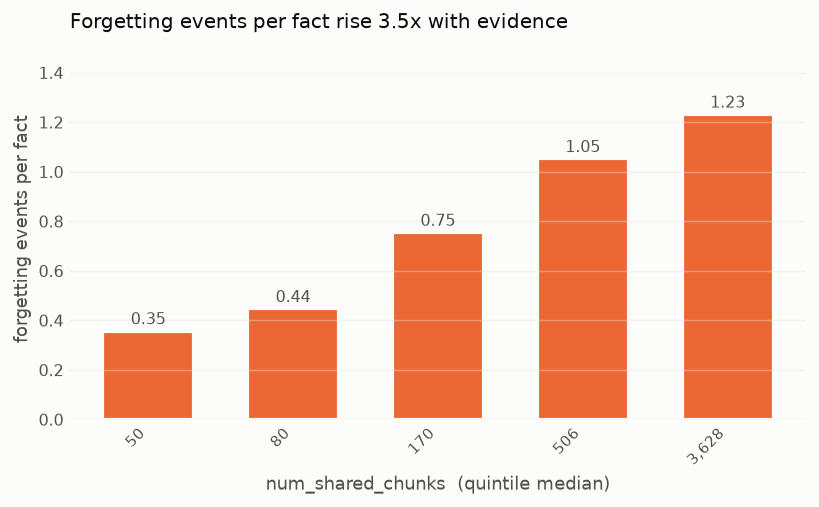

Spearman rho(num_shared_chunks, forgetting count) = +0.380   p = 3.3e-46


In [5]:
tab = by_fact_quintile(evidence)

fig, ax = plt.subplots(figsize=(6.4, 4.0))
x = np.arange(len(tab))
ax.bar(x, tab["events/fact"], 0.62, color=ORANGE, edgecolor=SURF, linewidth=1.2)
for i, v in enumerate(tab["events/fact"]):
    ax.text(i, v + .03, f"{v:.2f}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x, [f"{m:,.0f}" for m in tab["median freq"]], rotation=45, ha="right", fontsize=8.5)
ax.set_xlabel("num_shared_chunks  (quintile median)")
ax.set_ylabel("forgetting events per fact")
ax.set_ylim(0, tab["events/fact"].max() * 1.25)
ax.set_title("Forgetting events per fact rise 3.5x with evidence", loc="left")
clean(ax)
fig.tight_layout(); plt.show()

rho, p = spearmanr(evidence, forgot.sum(1))
print(f"Spearman rho(num_shared_chunks, forgetting count) = {rho:+.3f}   p = {p:.1e}")


---
## 3 — The correction: events rise 3.5×, but opportunities rise 12×

The count above is not normalised. Put the number of checkpoints at which each fact
is **correct at all** next to it, and the artefact is visible immediately: rare facts
are almost never correct, so they can barely ever be *observed* to forget. Dividing
events by opportunities reverses the sign.

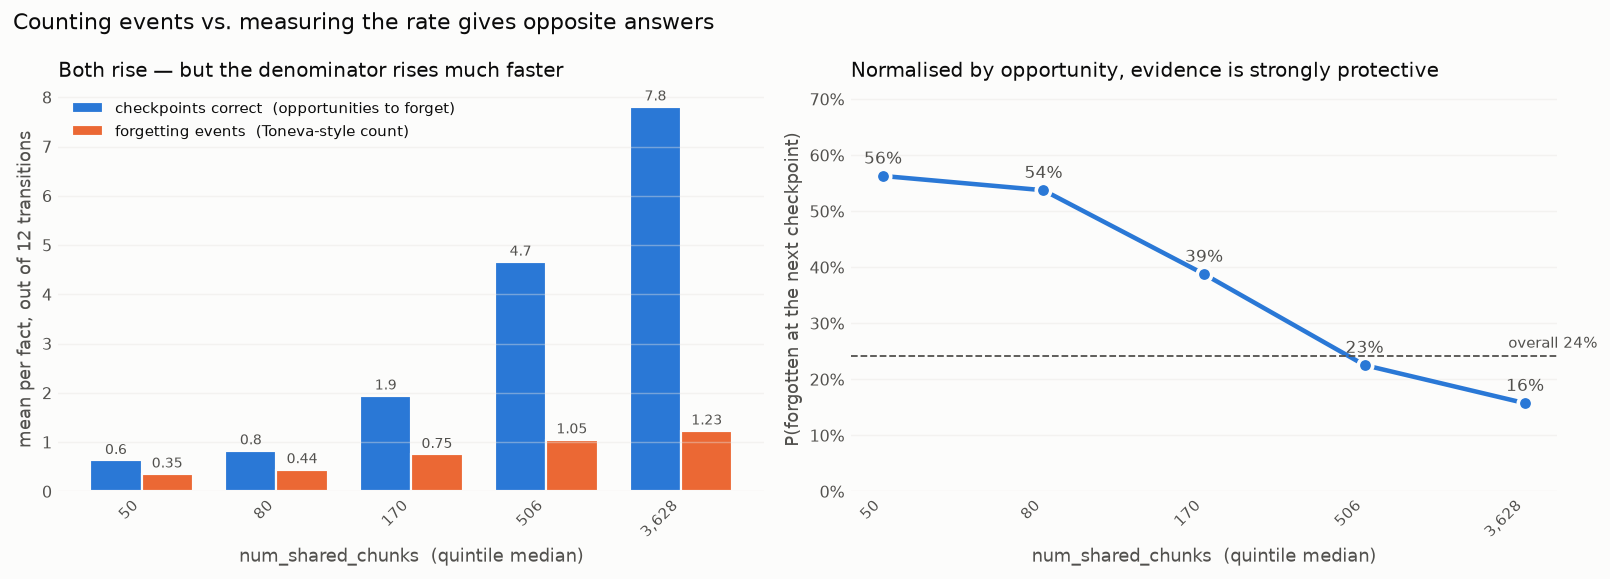

 quintile median freq  facts events/fact correct ckpts/fact hazard
        1          50    265        0.35               0.63  56.3%
        2          80    259        0.44               0.83  53.7%
        3         170    262        0.75               1.94  38.8%
        4         506    262        1.05               4.66  22.5%
        5       3,628    262        1.23               7.81  15.7%

events      x3.5 across quintiles
opportunity x12.4 across quintiles


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.4, 4.5))
w = 0.38

ax1.bar(x - w/2, tab["correct ckpts/fact"], w, color=BLUE, edgecolor=SURF, linewidth=1.2,
        label="checkpoints correct  (opportunities to forget)")
ax1.bar(x + w/2, tab["events/fact"], w, color=ORANGE, edgecolor=SURF, linewidth=1.2,
        label="forgetting events  (Toneva-style count)")
for i in range(len(tab)):
    ax1.text(i - w/2, tab["correct ckpts/fact"][i] + .13, f"{tab['correct ckpts/fact'][i]:.1f}",
             ha="center", fontsize=8, color=INK2)
    ax1.text(i + w/2, tab["events/fact"][i] + .13, f"{tab['events/fact'][i]:.2f}",
             ha="center", fontsize=8, color=INK2)
ax1.set_ylabel("mean per fact, out of 12 transitions")
ax1.set_title("Both rise — but the denominator rises much faster", loc="left")
ax1.legend(loc="upper left", fontsize=8.5)

ax2.plot(x, tab["hazard"], color=BLUE, lw=2.5, marker="o", ms=8,
         mfc=BLUE, mec=SURF, mew=2)
for i, h in enumerate(tab["hazard"]):
    ax2.text(i, h + .022, f"{h:.0%}", ha="center", fontsize=9.5, color=INK2)
ax2.axhline(BASE, color=INK2, ls="--", lw=1)
ax2.text(len(tab) - .55, BASE + .015, f"overall {BASE:.0%}", ha="right", fontsize=8.5, color=INK2)
ax2.set_ylim(0, tab["hazard"].max() * 1.28)
ax2.yaxis.set_major_formatter(PCT)
ax2.set_ylabel("P(forgotten at the next checkpoint)")
ax2.set_title("Normalised by opportunity, evidence is strongly protective", loc="left")

for ax in (ax1, ax2):
    ax.set_xticks(x, [f"{m:,.0f}" for m in tab["median freq"]], rotation=45, ha="right", fontsize=8.5)
    ax.set_xlabel("num_shared_chunks  (quintile median)")
    clean(ax)
fig.suptitle("Counting events vs. measuring the rate gives opposite answers",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout(); plt.show()

print(tab[["quintile", "median freq", "facts", "events/fact",
           "correct ckpts/fact", "hazard"]].to_string(index=False,
      formatters={"median freq": "{:,.0f}".format, "events/fact": "{:.2f}".format,
                  "correct ckpts/fact": "{:.2f}".format, "hazard": "{:.1%}".format}))
print(f"\nevents      x{tab['events/fact'].iloc[-1] / tab['events/fact'].iloc[0]:.1f} across quintiles")
print(f"opportunity x{tab['correct ckpts/fact'].iloc[-1] / tab['correct ckpts/fact'].iloc[0]:.1f} across quintiles")


---
## 4 — The hazard falls for both notions of frequency

Evidence for the fact and popularity of the subject are only weakly related, but both
are protective. Evidence is the stronger of the two, and it is also the better-behaved
one: its hazard falls monotonically across all five quintiles, whereas subject
popularity drops sharply out of the bottom quintile and is then essentially flat.
That is the right ordering — what protects a fact is how often the model saw *this
fact stated*, not how famous its subject is.

From here on the unit of analysis is the **transition**, so bins hold equal numbers of
at-risk observations rather than equal numbers of facts. The gradient is a little
flatter than in §3 (46 % → 12 % rather than 56 % → 16 %) for a mechanical reason: rare
facts contribute so few transitions that a transition-bin's bottom quintile has to
reach up into better-attested facts to fill itself. The Spearman correlations are
computed over the transitions directly and involve no binning at all.

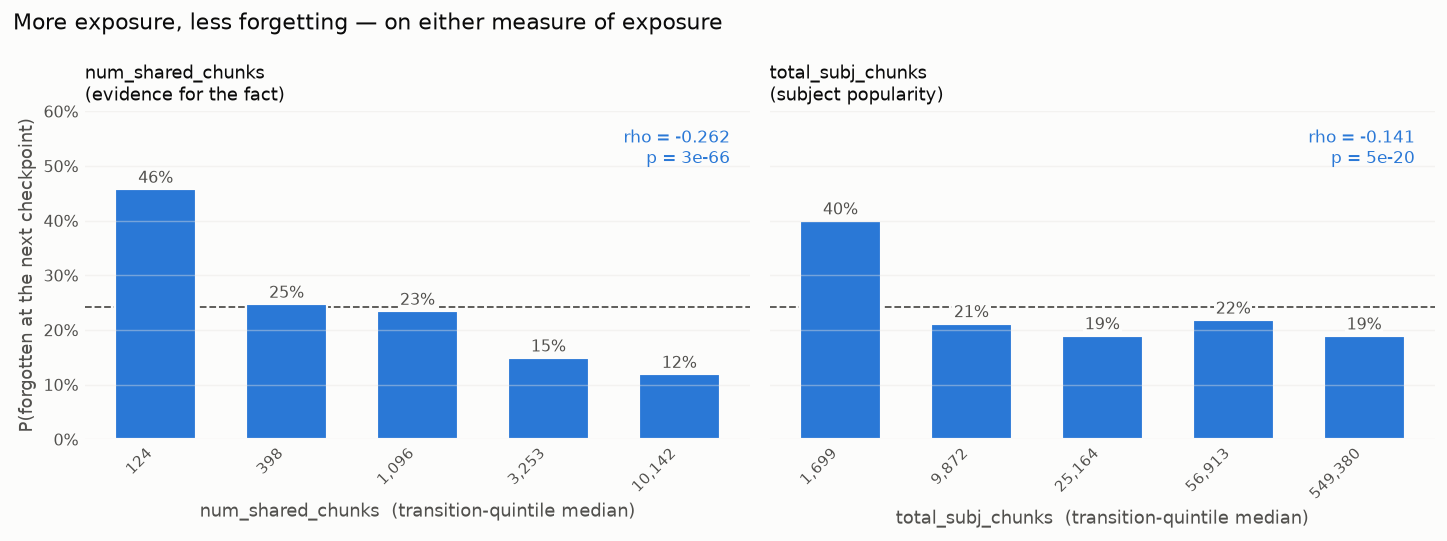

num_shared_chunks:  Q1 45.7% (n=831)  Q2 24.7% (n=838)  Q3 23.4% (n=833)  Q4 14.9% (n=827)  Q5 11.9% (n=825)
total_subj_chunks:  Q1 40.0% (n=831)  Q2 21.2% (n=832)  Q3 18.9% (n=850)  Q4 21.8% (n=821)  Q5 18.9% (n=820)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.2), sharey=True)
for ax, (name, v) in zip(axes, FREQ):
    t = by_transition_quintile(v)
    ax.bar(np.arange(len(t)), t["hazard"], 0.62, color=BLUE, edgecolor=SURF, linewidth=1.2)
    for i, h in enumerate(t["hazard"]):
        # surface-coloured bbox so a label never collides with the reference line
        ax.text(i, h + .012, f"{h:.0%}", ha="center", fontsize=9, color=INK2,
                bbox=dict(fc=SURF, ec="none", pad=1.0))
    ax.axhline(BASE, color=INK2, ls="--", lw=1, zorder=0)
    rho, p = spearmanr(v[f_idx], t_forgot)
    ax.annotate(f"rho = {rho:+.3f}\np = {p:.0e}", (0.97, 0.95), xycoords="axes fraction",
                ha="right", va="top", fontsize=9.5, color=BLUE)
    ax.set_xticks(np.arange(len(t)), [f"{m:,.0f}" for m in t["median freq"]],
                  rotation=45, ha="right", fontsize=8.5)
    ax.set_xlabel(name.splitlines()[0] + "  (transition-quintile median)")
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_ylim(0, 0.60)
    clean(ax)
axes[0].yaxis.set_major_formatter(PCT)
axes[0].set_ylabel("P(forgotten at the next checkpoint)")
fig.suptitle("More exposure, less forgetting — on either measure of exposure",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout(); plt.show()

for name, v in FREQ:
    t = by_transition_quintile(v)
    print(f"{name.splitlines()[0]}:  " +
          "  ".join(f"Q{r.quintile} {r.hazard:.1%} (n={r.n})" for r in t.itertuples()))


---
## 5 — Two ways the result could still be an artefact

**(a) It could just be "well-stored facts survive".** Frequent facts have a higher
gold-answer probability, and high gold probability is already known (§ elsewhere in
this project) to predict survival. If frequency only mattered *through* current
confidence, the relationship should vanish once confidence is held fixed. Left panel:
the hazard curve is recomputed inside each gold-probability quintile. It does not
vanish — every stratum keeps a downward slope.

**(b) It could be lenient scoring.** `correct` is a substring match, so a fact can be
"correct" by luck without the gold answer being the model's top prediction, and luck
is easier to lose. The right panel restricts to transitions where the gold answer was
genuinely **top-1** — under a third of them. The slope survives, at a lower base rate.

Bin edges are computed once on all transitions, so the two curves in (b) are directly
comparable; any bin left with fewer than 30 observations is dropped rather than
plotted as a rate estimated from a handful of points.

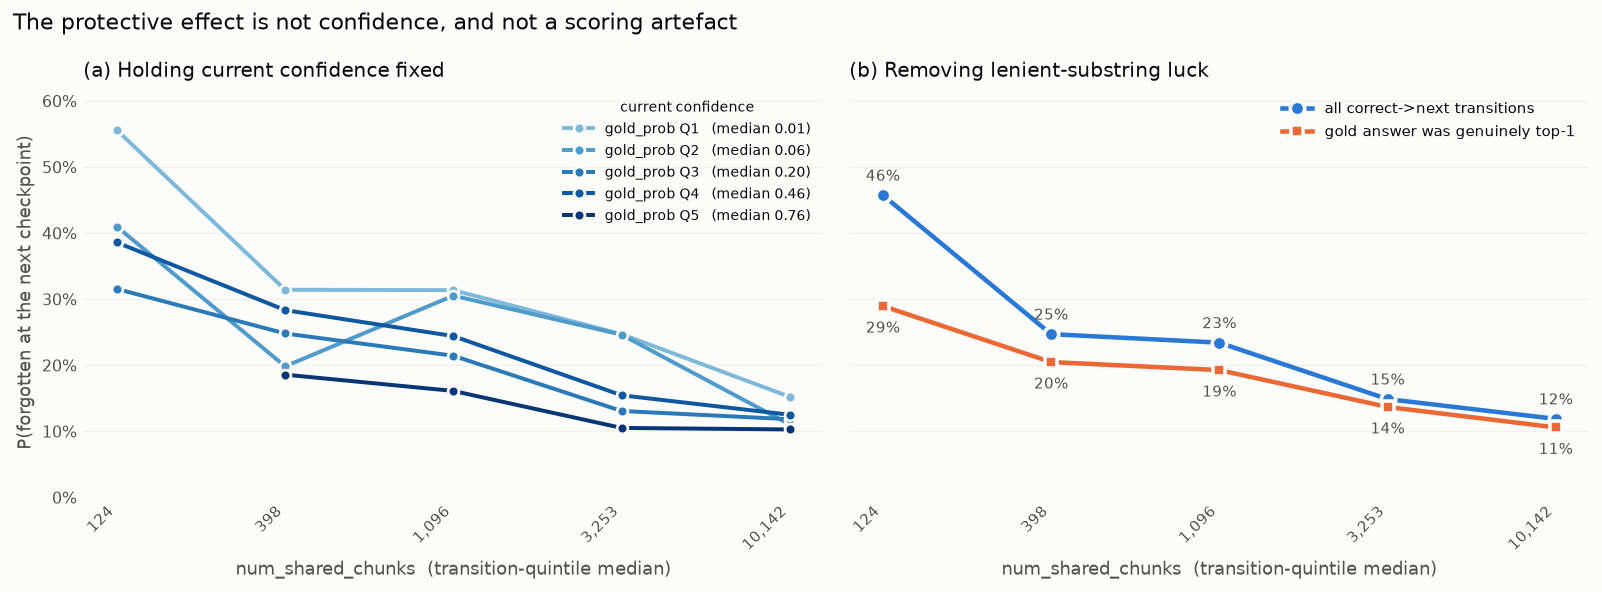

Spearman rho(frequency, forgotten-next), overall and averaged within gold_prob strata:
  num_shared_chunks    overall -0.262   within-stratum mean -0.199
  total_subj_chunks    overall -0.141   within-stratum mean -0.120

strict top-1 transitions: 1628 of 4154, overall hazard 15.7% (vs 24.1% lenient)
  by evidence quintile: Q1 28.9% (n=76)  Q2 20.5% (n=210)  Q3 19.3% (n=379)  Q4 13.7% (n=519)  Q5 10.6% (n=444)


In [8]:
all_t    = by_transition_quintile(evidence)                 # every at-risk transition
strict_t = by_transition_quintile(evidence, keep=t_top1)    # ... where gold was top-1
xq       = np.arange(len(all_t))
ev_bin   = pd.qcut(evidence[f_idx], 5, labels=False, duplicates="drop").astype(int)
gp_bin   = pd.qcut(t_goldprob,      5, labels=False, duplicates="drop").astype(int)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(12.4, 4.6), sharey=True)

# --- (a) the same curve, inside each gold-probability stratum -------------------
shades = plt.get_cmap("Blues")(np.linspace(0.45, 0.98, gp_bin.max() + 1))
for g in range(gp_bin.max() + 1):
    sel = gp_bin == g
    hz  = [t_forgot[sel & (ev_bin == b)].mean() if (sel & (ev_bin == b)).sum() >= 30 else np.nan
           for b in range(ev_bin.max() + 1)]
    axL.plot(xq, hz, color=shades[g], lw=2.2, marker="o", ms=6, mec=SURF, mew=1.5,
             label=f"gold_prob Q{g+1}   (median {np.median(t_goldprob[sel]):.2f})")
axL.legend(fontsize=8, loc="upper right", title="current confidence", title_fontsize=8)
axL.set_ylabel("P(forgotten at the next checkpoint)")
axL.set_title("(a) Holding current confidence fixed", loc="left")

# --- (b) strict top-1 scoring ---------------------------------------------------
axR.plot(xq, all_t["hazard"], color=BLUE, lw=2.5, marker="o", ms=8, mec=SURF, mew=2,
         label="all correct->next transitions")
axR.plot(xq, strict_t["hazard"], color=ORANGE, lw=2.5, marker="s", ms=7, mec=SURF, mew=2,
         label="gold answer was genuinely top-1")
for i in xq:
    axR.text(i, all_t["hazard"][i] + .022, f"{all_t['hazard'][i]:.0%}",
             ha="center", fontsize=8.5, color=INK2)
    axR.text(i, strict_t["hazard"][i] - .040, f"{strict_t['hazard'][i]:.0%}",
             ha="center", fontsize=8.5, color=INK2)
axR.legend(fontsize=8.5, loc="upper right")
axR.set_title("(b) Removing lenient-substring luck", loc="left")

axL.yaxis.set_major_formatter(PCT)
axL.set_ylim(0, 0.62)
for ax in (axL, axR):
    ax.set_xticks(xq, [f"{m:,.0f}" for m in all_t["median freq"]], rotation=45, ha="right", fontsize=8.5)
    ax.set_xlabel("num_shared_chunks  (transition-quintile median)")
    clean(ax)
fig.suptitle("The protective effect is not confidence, and not a scoring artefact",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout(); plt.show()

print("Spearman rho(frequency, forgotten-next), overall and averaged within gold_prob strata:")
for name, v in FREQ:
    w = [spearmanr(v[f_idx][gp_bin == g], t_forgot[gp_bin == g])[0]
         for g in range(gp_bin.max() + 1) if (gp_bin == g).sum() > 50]
    print(f"  {name.splitlines()[0]:20s} overall {spearmanr(v[f_idx], t_forgot)[0]:+.3f}   "
          f"within-stratum mean {np.mean(w):+.3f}")
print(f"\nstrict top-1 transitions: {t_top1.sum()} of {t_forgot.size}, "
      f"overall hazard {t_forgot[t_top1].mean():.1%} (vs {BASE:.1%} lenient)")
print("  by evidence quintile: " +
      "  ".join(f"Q{r.quintile} {r.hazard:.1%} (n={r.n})" for r in strict_t.itertuples()))


---
## 6 — Conclusion

**The premise is not merely unsupported; it is inverted.** Once forgetting is measured
as a *rate* rather than a *count*, evidence for a fact is strongly protective:

| statistic (by `num_shared_chunks` quintile) | lowest | highest | direction |
|---|---|---|---|
| forgetting **count** per fact | 0.35 | 1.23 | rises 3.5× (ρ = +0.38) |
| checkpoints correct per fact | 0.63 | 7.81 | rises 12.4× |
| forgetting **hazard** | **56 %** | **16 %** | **falls** (ρ = −0.26, p ≈ 1e-63) |

and the fall survives both obvious objections — it holds inside every
gold-probability stratum (mean within-stratum ρ ≈ −0.20) and under strict top-1
scoring (29 % → 11 %). Subject popularity is protective too, but more weakly
(ρ ≈ −0.14), as expected: what protects a fact is having *the fact itself* attested,
not having a famous subject.

The whole appearance of the opposite result comes from the denominator. Rare facts in
this slice are correct at fewer than one checkpoint out of twelve on average, so they
almost never get the chance to be seen forgetting; well-attested facts are correct
most of the time and accumulate events simply by being eligible.

> **Frequency protects against forgetting.** What rises with frequency is the raw
> count of forgetting events, and that rise is entirely a rise in opportunity.

This puts LMEnt **in agreement** with Kandpal et al. (2023) and Mallen et al. (2023)
on the recall side and with Chang et al. (2024) on the durability side, rather than
contradicting them.

**Caveats.**

1. **Range restriction.** This is the top-10 % exposure slice; the lowest quintile still has ≈ 42 supporting chunks. Nothing here speaks to the genuine long tail.
2. **Correlational.** Frequency is not randomised — it travels with entity type, relation, and text style. The confidence-stratified result rules out one mediator, not all of them.
3. **Direction of the residual risk.** Frequency is the protective variable; the one factor in this feature set that *raises* the hazard is competition between facts sharing a subject's competitive word — a small effect (≈ 21 % → 32 %) that is analysed separately and deliberately left out of this notebook to keep the frequency result clean.